# 02 · PlantNet-300K baseline: training progress

Roadmap Phase 1 - a from-scratch replica of the official PlantNet-300K
paper's ResNet-18 baseline (`configs/plantnet_baseline.json`), trained
remotely on the home PC's GTX 1070 (`scripts/remote/`, `train.py`). No
class-imbalance handling and no toxicity-aware loss here - those are
Phases 2 and 3. This notebook only reports what the model is doing;
nothing here feeds back into training.

**This is a live notebook, not a one-off report.** Every cell below
re-fetches the run's log from the remote host and re-plots from whatever
has completed by the time you run it - re-run top to bottom any time to
see current progress. Nothing is hardcoded to today's numbers.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from plant_toxicity_checker import training_log

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

RUN_NAME = "plantnet-baseline"
CONFIG_EPOCHS = 30  # configs/plantnet_baseline.json

## 1 · Fetch and parse the run's log

`fetch_all_epochs` doesn't just read one log file: if the run was ever
paused and resumed (`train.sh ... --resume`), each resume gets its own
tmux session/log name while continuing the *same* run's checkpoints -
so a run's full history can be split across several log files on disk.
This finds every log fragment for `RUN_NAME`, merges them, and sorts by
epoch number, so a pause/resume never loses epochs from this view.

In [2]:
df = pd.DataFrame(training_log.fetch_all_epochs(RUN_NAME))
print(f"{len(df)} epoch(s) completed so far")
df

18 epoch(s) completed so far


,epoch,total_epochs,train_loss,val_top1,val_top5,time_seconds
0,1,30,2.0175,0.6496,0.8653,5182.1
1,2,30,1.3559,0.6866,0.8919,5239.6
2,3,30,1.1673,0.7196,0.9074,5229.8
3,4,30,1.0583,0.7373,0.9185,5199.7
4,5,30,0.9849,0.7405,0.9194,5174.0
5,6,30,0.9340,0.7395,0.9200,5183.4
6,7,30,0.8938,0.7350,0.9220,5123.1
7,8,30,0.8635,0.7413,0.9248,5173.0
8,9,30,0.8362,0.7470,0.9260,5178.2
9,10,30,0.8122,0.7473,0.9282,5287.4


## 2 · Progress over time

Left: training loss (should fall). Right: validation top-1/top-5
accuracy (should rise). This is the graph to watch - re-run the cells
above and this one any time to pull in whatever's finished since.

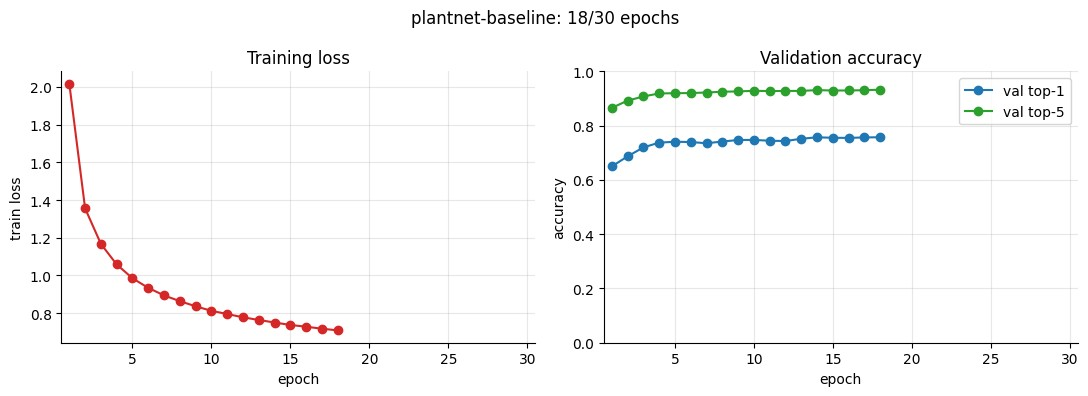

In [3]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))

ax_loss.plot(df["epoch"], df["train_loss"], "o-", color="#d62728")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("train loss")
ax_loss.set_title("Training loss")
ax_loss.set_xlim(0.5, CONFIG_EPOCHS + 0.5)
ax_loss.grid(True, alpha=0.3)

ax_acc.plot(df["epoch"], df["val_top1"], "o-", label="val top-1", color="#1f77b4")
ax_acc.plot(df["epoch"], df["val_top5"], "o-", label="val top-5", color="#2ca02c")
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("accuracy")
ax_acc.set_title("Validation accuracy")
ax_acc.set_ylim(0, 1)
ax_acc.set_xlim(0.5, CONFIG_EPOCHS + 0.5)
ax_acc.grid(True, alpha=0.3)
ax_acc.legend()

fig.suptitle(f"{RUN_NAME}: {len(df)}/{CONFIG_EPOCHS} epochs")
fig.tight_layout()
plt.show()

Same two series, log-scaled y-axis. Loss differences that look tiny on a linear scale (e.g. late-training epochs) are easier to read here; for accuracy, a log scale makes the *error rate* shrinking (1 - accuracy getting smaller) more visible than the raw accuracy plot does.

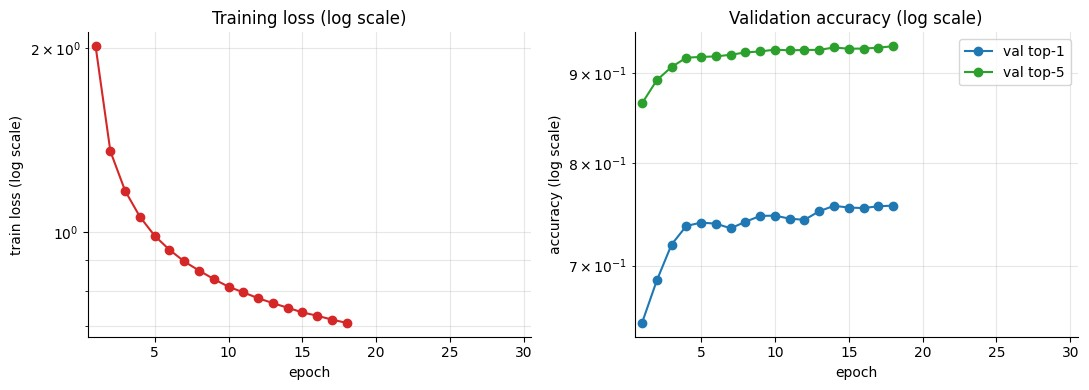

In [4]:
fig, (ax_loss_log, ax_acc_log) = plt.subplots(1, 2, figsize=(11, 4))

ax_loss_log.plot(df["epoch"], df["train_loss"], "o-", color="#d62728")
ax_loss_log.set_yscale("log")
ax_loss_log.set_xlabel("epoch")
ax_loss_log.set_ylabel("train loss (log scale)")
ax_loss_log.set_title("Training loss (log scale)")
ax_loss_log.set_xlim(0.5, CONFIG_EPOCHS + 0.5)
ax_loss_log.grid(True, which="both", alpha=0.3)

ax_acc_log.plot(df["epoch"], df["val_top1"], "o-", label="val top-1", color="#1f77b4")
ax_acc_log.plot(df["epoch"], df["val_top5"], "o-", label="val top-5", color="#2ca02c")
ax_acc_log.set_yscale("log")
ax_acc_log.set_xlabel("epoch")
ax_acc_log.set_ylabel("accuracy (log scale)")
ax_acc_log.set_title("Validation accuracy (log scale)")
ax_acc_log.set_xlim(0.5, CONFIG_EPOCHS + 0.5)
ax_acc_log.grid(True, which="both", alpha=0.3)
ax_acc_log.legend()

fig.tight_layout()
plt.show()

## 3 · Current status

In [5]:
latest = df.iloc[-1]
mean_epoch_time = df["time_seconds"].mean()
remaining_epochs = CONFIG_EPOCHS - len(df)
remaining_hours = remaining_epochs * mean_epoch_time / 3600

print(f"Latest: epoch {int(latest['epoch'])}/{CONFIG_EPOCHS}")
print(f"  train_loss = {latest['train_loss']:.4f}")
print(f"  val_top1   = {latest['val_top1']:.1%}")
print(f"  val_top5   = {latest['val_top5']:.1%}")
print()
print(f"Mean epoch time so far: {mean_epoch_time / 60:.1f} min")
if remaining_epochs > 0:
    print(f"Epochs remaining: {remaining_epochs}")
    print(f"Estimated time remaining: {remaining_hours:.1f}h "
          f"(assumes the current pace holds)")
else:
    print("All configured epochs complete.")

Latest: epoch 18/30
  train_loss = 0.7084
  val_top1   = 75.7%
  val_top5   = 93.2%

Mean epoch time so far: 80.0 min
Epochs remaining: 12
Estimated time remaining: 16.0h (assumes the current pace holds)


## Training setup (for reference)

| | |
|---|---|
| Model | ResNet-18, ImageNet-pretrained |
| Optimizer | SGD, momentum 0.9, Nesterov, weight decay 1e-4 |
| LR schedule | 0.01, ×0.1 at epochs 20 and 25 |
| Batch size | 32 |
| Loss | plain cross-entropy (no class weighting) |
| Epochs | 30 |
| Label space | all 1,000 PlantNet-300K species |

Exact values: `configs/plantnet_baseline.json`. Hardware: GTX 1070 (8GB,
Pascal), trained via `scripts/remote/`. Training is disk-I/O-bound, not
GPU-compute-bound, on this machine (the dataset lives on a spinning HDD,
not the SSD) - GPU utilization sits around 0-40% throughout; `time` above
is dominated by data loading, not the model's forward/backward pass.

**Not yet done:** comparing these numbers against the paper's own
published baseline results - that's a Roadmap Phase 4 task, once this
run finishes and the comparison can be made honestly rather than against
a half-remembered figure.